# Human perivascular: cell-type annotation (stage 04c)

Every cluster of the re-integrated perivascular lineage is assigned one cell type (or EXCLUDE). Labels are the vocabulary in resources/annotation_vocabulary.yaml.

Clustering: `data/interim/latent_human_perivascular.h5ad`, column `leiden_scVI_3.0`. Decisions: `resources/annotations/human_perivascular.csv`, one
row per cluster with the markers that justify the label in `note`. Nothing in this
notebook assigns a label; it shows the evidence the table was decided from.

In [1]:
import warnings
from pathlib import Path

import anndata as ad
import numpy as np
import pandas as pd
import scanpy as sc

# Notebook kernels start in notebooks/annotation/, so the repo root is two levels up.
REPO = Path("../..").resolve()
if not (REPO / "resources/annotations").is_dir():
    raise FileNotFoundError(f"{REPO} is not the repository root")
SPECIES, LEVEL, RESOLUTION = "human", "perivascular", "leiden_scVI_3.0"
OBJECT = REPO / "data/interim/latent_human_perivascular.h5ad"
TABLE = REPO / "resources/annotations/human_perivascular.csv"
PANEL = ['PECAM1', 'FLT1', 'CLDN5', 'CDH5', 'PDGFRB', 'RGS5', 'ACTA2', 'CDH1', 'PDGFRA', 'PTPRC', 'VWF', 'PROX1', 'LYVE1', 'CCL21', 'PDPN']
sc.settings.set_figure_params(dpi=80, frameon=False)
pd.set_option("display.max_colwidth", 200)

## 1. The committed table

In [2]:
table = pd.read_csv(TABLE, dtype={"cluster": str})
table.set_index("cluster")

,label,n_cells,res,note
cluster,,,,
0,endothelial_blood,124,leiden_scVI_3.0,"PECAM1 0.88; FLT1 0.88; VWF 0.94; PROX1 0.12 | top vs level: INSR 0.94, AFF3 0.90, PKP4 0.94"
1,endothelial_blood,94,leiden_scVI_3.0,"PECAM1 0.93; FLT1 0.78; VWF 0.97; PROX1 0.03 | top vs level: AFF3 0.95, PCDH17 0.87, SLCO2A1 0.97"
2,EXCLUDE,53,leiden_scVI_3.0,"EXCLUDE: doublet score med 10.50 (level q75 9.15), genes med 4529 (level q25 1408), 0.81 co-express 2+ lineage panels (level 0.40); panels: perivascular 0.70, endometrial_fibroblasts 0.58, smooth_..."
3,EXCLUDE,110,leiden_scVI_3.0,"EXCLUDE: doublet score med 9.15 (level q75 9.15), genes med 3848 (level q25 1408), 0.89 co-express 2+ lineage panels (level 0.40); panels: endometrial_fibroblasts 0.92, perivascular 0.78, smooth_m..."
4,EXCLUDE,76,leiden_scVI_3.0,"EXCLUDE: doublet score med 11.59 (level q75 9.15), genes med 3670 (level q25 1408), 0.87 co-express 2+ lineage panels (level 0.40); panels: endometrial_fibroblasts 0.93, perivascular 0.80, smooth_..."
5,EXCLUDE,105,leiden_scVI_3.0,"EXCLUDE: doublet score med 0.01 (level q75 9.15), genes med 1786 (level q25 1408), 0.67 co-express 2+ lineage panels (level 0.40); panels: endometrial_fibroblasts 0.77, perivascular 0.63, smooth_m..."
6,endothelial_lymph,85,leiden_scVI_3.0,"PROX1 0.91; LYVE1 0.07; CCL21 0.69; FLT1 0.02 | top vs level: PPFIBP1 0.99, SEMA3D 0.93, TFPI 1.00"
7,endothelial_lymph,125,leiden_scVI_3.0,"PROX1 0.90; LYVE1 0.05; CCL21 0.29; FLT1 0.05 | top vs level: RELN 0.98, PIEZO2 0.90, CHSY3 0.95"
8,endothelial_lymph,74,leiden_scVI_3.0,"PROX1 0.93; LYVE1 0.19; CCL21 0.59; FLT1 0.03 | top vs level: CD36 0.96, PPFIBP1 0.97, PKHD1L1 0.91"


## 2. The clustered object (must carry exactly the clusters in the table)

In [3]:
adata = ad.read_h5ad(OBJECT)
adata.obs["cluster"] = adata.obs[RESOLUTION].astype(str)
in_object, in_table = set(adata.obs["cluster"]), set(table["cluster"])
if in_object != in_table:
    raise ValueError(f"cluster sets differ: object-only {sorted(in_object - in_table)}, "
                     f"table-only {sorted(in_table - in_object)}")
labels = table.set_index("cluster")["label"]
adata.obs["label"] = adata.obs["cluster"].map(labels).astype("category")
print(adata.n_obs, "nuclei;", len(in_object), "clusters")
print(adata.obs["label"].value_counts().to_dict())

1813 nuclei; 21 clusters
{'endothelial_blood': 828, 'endothelial_lymph': 506, 'EXCLUDE': 479}


In [4]:
# Expression for the dot plot: CP10K log1p from raw counts.
counts = adata.layers["counts"] if "counts" in adata.layers else adata.X
expr = ad.AnnData(X=counts.copy(), obs=adata.obs[["cluster", "label"]].copy(),
                  var=adata.var[[]].copy())
sc.pp.normalize_total(expr, target_sum=1e4)
sc.pp.log1p(expr)
genes = [g for g in PANEL if g in expr.var_names]
missing = sorted(set(PANEL) - set(genes))
if missing:
    print("not in this object:", missing)

## 3. Marker dot plot by cluster

Dot size is the fraction of nuclei in which the gene is detected, colour the mean
log1p CP10K. Clusters are grouped by their label; EXCLUDE clusters are last.

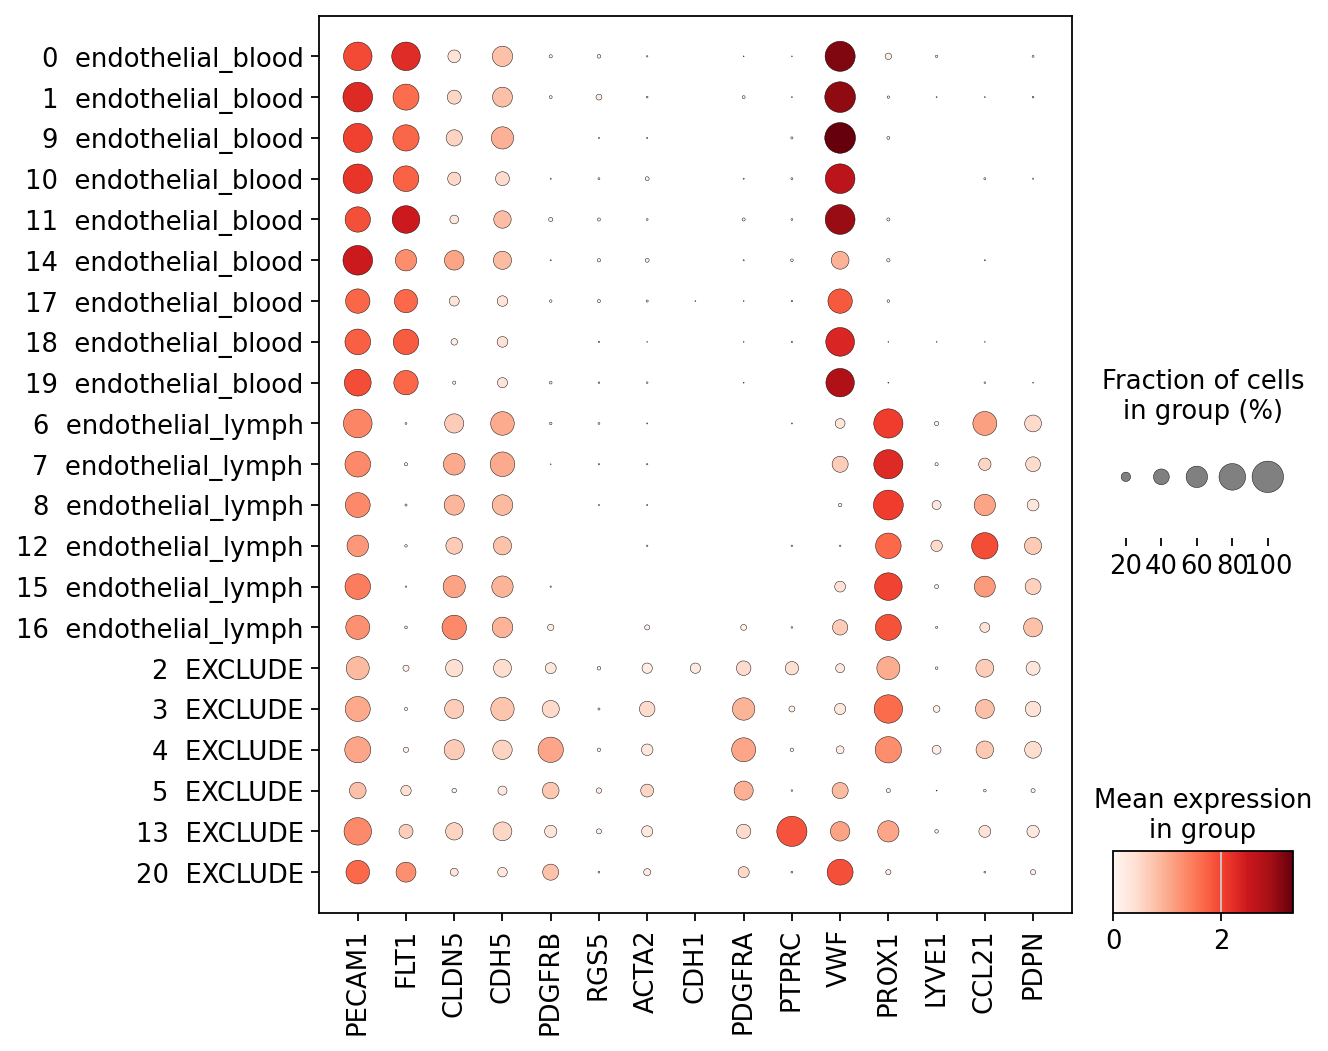

In [5]:
def sort_key(c):
    return (labels[c] == "EXCLUDE", labels[c], int(c) if c.isdigit() else c)

order = sorted(in_object, key=sort_key)
expr.obs["cluster_labelled"] = pd.Categorical(
    [f"{c}  {labels[c]}" for c in expr.obs["cluster"]],
    categories=[f"{c}  {labels[c]}" for c in order])
sc.pl.dotplot(expr, genes, groupby="cluster_labelled", standard_scale=None,
              figsize=(0.32 * len(genes) + 3, 0.28 * len(order) + 1.5))

## 4. QC per cluster

Median DoubletDetection score and genes per nucleus per cluster, with the lineage
median for reference (the CSV notes quote the lineage's doublet 75th and genes 25th
percentiles, from `tools/cluster_marker_table.py`). A high doublet score together
with markers of another lineage (section 6) is what an EXCLUDE call rests on; a
moderate score alone is not (cycling clusters score around 1 throughout this
dataset).

In [6]:
qc_cols = [c for c in ("doubletdetection_doublet_score", "n_genes_by_counts",
                       "total_counts") if c in adata.obs]
qc = adata.obs.groupby("cluster", observed=True)[qc_cols].median().loc[order]
qc.insert(0, "n", adata.obs["cluster"].value_counts().loc[order])
qc.insert(1, "label", labels.loc[order])
qc.loc["lineage median"] = [adata.n_obs, ""] + list(adata.obs[qc_cols].median())
qc.round(2)

,n,label,doubletdetection_doublet_score,n_genes_by_counts,total_counts
cluster,,,,,
0,124,endothelial_blood,0.02,2275.5,4362.0
1,94,endothelial_blood,0.44,2121.0,3817.0
9,70,endothelial_blood,0.02,2400.5,4443.5
10,80,endothelial_blood,0.02,2109.0,3865.0
11,44,endothelial_blood,0.23,1465.0,2673.5
14,79,endothelial_blood,0.00,1683.0,2820.0
17,111,endothelial_blood,0.00,1318.0,2363.0
18,122,endothelial_blood,0.00,1499.0,2589.5
19,104,endothelial_blood,0.00,1519.0,2482.5


## 5. UMAP by cluster and by label

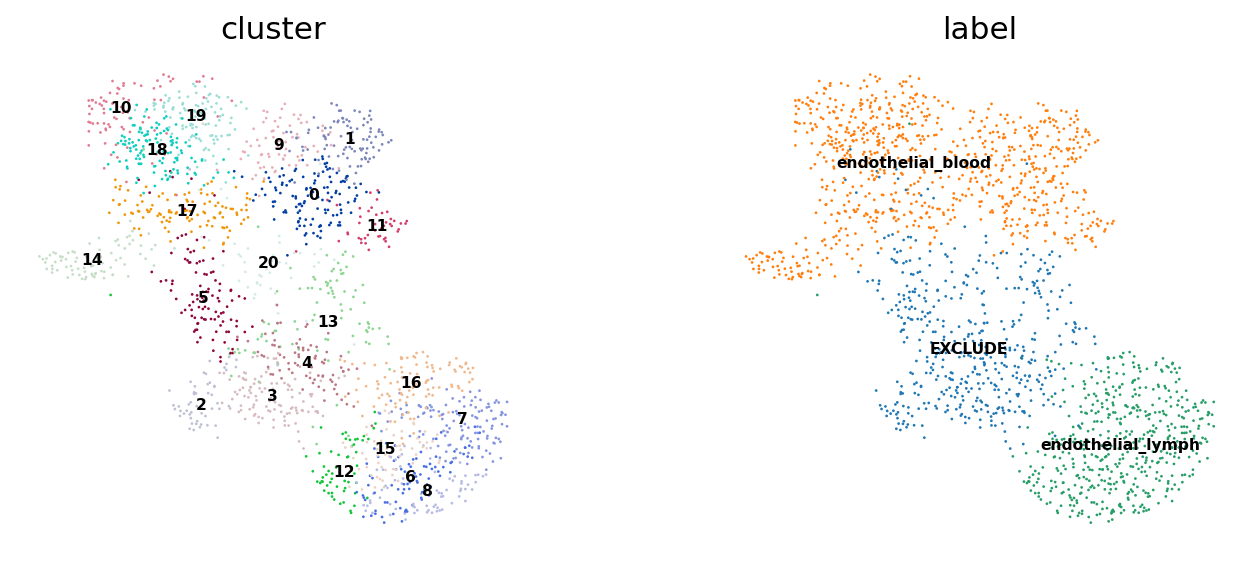

In [7]:
umap_key = next((k for k in ("X_umap_scVI", "X_umap") if k in adata.obsm), None)
if umap_key is None:
    latent_key = next(k for k in adata.obsm if "scVI" in k or "scvi" in k)
    sc.pp.neighbors(adata, use_rep=latent_key, n_neighbors=15, random_state=0)
    sc.tl.umap(adata, random_state=0)
    umap_key = "X_umap"
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    sc.pl.embedding(adata, basis=umap_key, color=["cluster", "label"], legend_loc="on data",
                    legend_fontsize=7, size=6, ncols=2, wspace=0.25)

## 6. EXCLUDE clusters

Detection of each lineage's markers inside the excluded clusters, next to the
lineage-wide detection; a cluster is excluded when it carries another lineage's
programme (doublets) or too little RNA to call.

In [8]:
excluded = [c for c in order if labels[c] == "EXCLUDE"]
if excluded:
    detected = pd.DataFrame(
        {c: np.asarray((expr[expr.obs["cluster"] == c, genes].X > 0).mean(0)).ravel()
         for c in excluded},
        index=genes)
    detected["lineage"] = np.asarray((expr[:, genes].X > 0).mean(0)).ravel()
    display(detected.round(2).T)
else:
    print("no EXCLUDE clusters in this table")

,PECAM1,FLT1,CLDN5,CDH5,PDGFRB,RGS5,ACTA2,CDH1,PDGFRA,PTPRC,VWF,PROX1,LYVE1,CCL21,PDPN
2,0.66,0.11,0.45,0.47,0.25,0.06,0.23,0.23,0.36,0.32,0.19,0.66,0.04,0.47,0.34
3,0.74,0.05,0.52,0.67,0.45,0.03,0.39,0.00,0.64,0.11,0.25,0.87,0.13,0.51,0.39
4,0.78,0.09,0.55,0.53,0.75,0.05,0.26,0.00,0.70,0.05,0.16,0.79,0.18,0.46,0.43
5,0.43,0.23,0.08,0.19,0.43,0.10,0.30,0.00,0.51,0.02,0.41,0.07,0.01,0.04,0.07
13,0.84,0.34,0.45,0.51,0.29,0.09,0.25,0.00,0.35,0.95,0.53,0.59,0.05,0.27,0.29
20,0.68,0.55,0.16,0.20,0.41,0.02,0.14,0.00,0.25,0.02,0.77,0.09,0.00,0.02,0.09
lineage,0.77,0.41,0.38,0.47,0.14,0.04,0.09,0.01,0.14,0.08,0.56,0.40,0.05,0.22,0.19
